In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math

# Plot 1

Plot of single particle in z direction, as function of time

I will use the n=4000 data for this with RK4

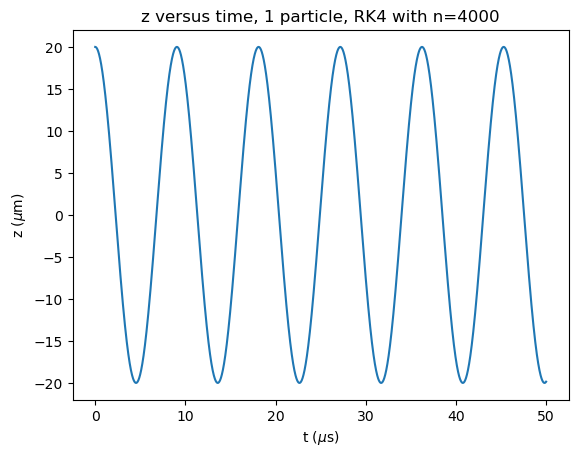

In [8]:
data = pd.read_csv("../Project3_Outputs/oneparticle_n4000_RK4.csv")

#plot
plt.plot(data['time'], data['z'])
plt.title('z versus time, 1 particle, RK4 with n=4000')
plt.xlabel(r't ($\mu$s)')
plt.ylabel(r'z ($\mu$m)')
plt.savefig('../Figures/z vs time.pdf', bbox_inches='tight')

In [9]:
#set trap constants
V_0 = 2.41e6
B_0 = 96.5
d = 500 #micro meters
m = 40.08
q = 1

#set omega constants
omega_z = np.sqrt((2*q*V_0)/(m*d*d))
print(omega_z)
print((2*math.pi)/omega_z)

0.6935689757707568
9.059207557831058


# Plots 2 and 3
Relative error compared to analytical solution

For various n, all in same plot

Both RK4 and FE

In [ ]:
#Helper functions
#Function for hard-coded analytical solutions
def analytical_solution(n, m, q, r_0, v_0):
    #inputs########
    # n=number of steps
    # m=particle mass in units
    # q=particle charge in e
    # r_0 = list of initial position (x,y,z)
    # v_0 = list of initial velocity (x,y,z)

    #Outputs#########
    # output_r = position dataframe as (t, x, y, z)

    stepsize = 50/n
    t = np.arange((0+stepsize), (50+stepsize), stepsize)

    #set trap constants
    V_0 = 2.41e6
    B_0 = 96.5
    d = 500 #micro meters

    #set omega constants
    ##LLM note: debugged with UiO GPT --> identified that I had forgotten to take the root of omega_z
    omega_z = np.sqrt((2*q*V_0)/(m*d*d))
    omega_0 = (q*B_0)/m

    #z solution
    #Given in project description as z(t)=z_0 cos(omega_z*t)
    z_solution = [r_0[2]]
    z = r_0[2]*np.cos(omega_z*t)
    z_solution.extend(z)

    #Calculate A+ and A- for the x and y solutions
    omegaplus = (omega_0 + math.sqrt(np.square(omega_0) - 2*np.square(omega_z)))/2
    print(omegaplus)
    omegaminus = (omega_0 - math.sqrt(np.square(omega_0) - 2*np.square(omega_z)))/2
    print(omegaminus)
    Aplus = (v_0[1] + omegaminus*r_0[0])/(omegaplus - omegaminus)
    Aminus = (v_0[1] + omegaplus*r_0[0])/(omegaplus - omegaminus)
    phiplus = math.pi
    phiminus = 0

    #xy plane solution
    x_solution = [r_0[0]]
    x = Aplus*np.cos(omegaplus*t + phiplus) + Aminus*np.cos(omegaminus*t + phiminus)
    x_solution.extend(x)
    y_solution = [r_0[1]]
    y = -Aplus*np.sin(omegaplus*t + phiplus) - Aminus*np.sin(omegaminus*t + phiminus)
    y_solution.extend(y)

    t_solution = [0]
    t_solution.extend(t)

    return pd.DataFrame({'t': t_solution, 'x': x_solution, 'y': y_solution, 'z': z_solution})

def relative_error(ytrue, ypred):
    r_i = np.sqrt(np.square(ypred['x']) + np.square(ypred['y']) + np.square(ypred['z']))
    r_true = np.sqrt(np.square(ytrue['x']) + np.square(ytrue['y']) + np.square(ytrue['z']))
    return np.abs(r_true - r_i)/r_true


2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776


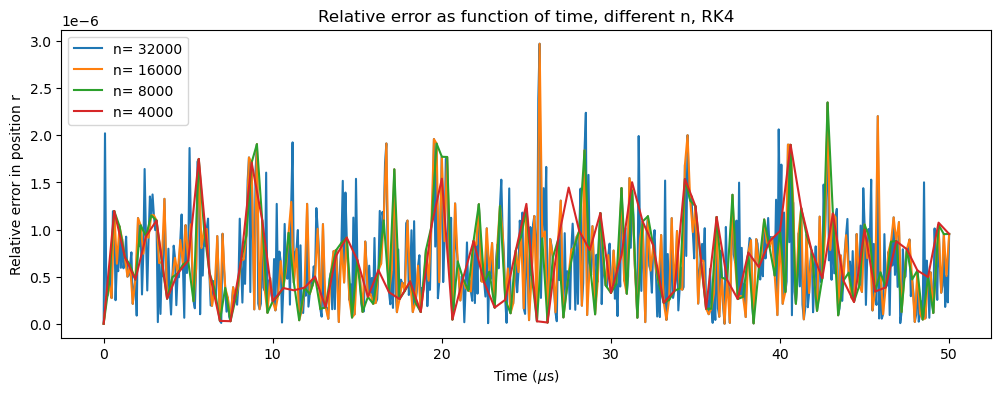

In [11]:
nvals = [32000,16000,8000,4000]
pathslist = ["../Project3_Outputs/oneparticle_n32000_RK4.csv", "../Project3_Outputs/oneparticle_n16000_RK4.csv","../Project3_Outputs/oneparticle_n8000_RK4.csv","../Project3_Outputs/oneparticle_n4000_RK4.csv"]

plt.figure(figsize=(12, 4)) 
for i in range(len(pathslist)):
    data = pd.read_csv(pathslist[i])
    analytical = analytical_solution(nvals[i], 40.08, 1, [20,0,20], [0,25,0])
    plt.plot(data['time'][::50], relative_error(analytical, data)[::50], label=f"n= {nvals[i]}")
plt.legend()
plt.xlabel(r'Time ($\mu$s)')
plt.ylabel('Relative error in position r')
plt.title('Relative error as function of time, different n, RK4')
plt.savefig('../Figures/Error vs n, RK4.pdf', bbox_inches='tight')

2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776
2.3032591417812354
0.10442548895728776


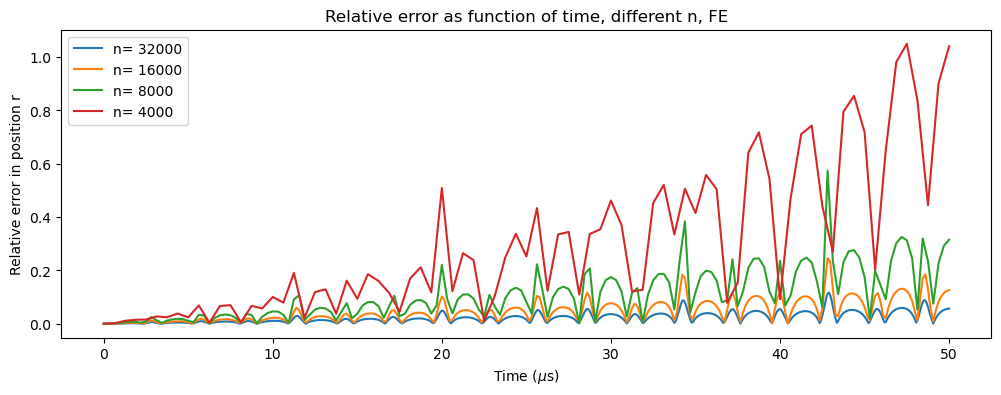

In [12]:
nvals = [32000,16000,8000,4000]
pathslist = ["../Project3_Outputs/oneparticle_n32000_FE.csv", "../Project3_Outputs/oneparticle_n16000_FE.csv","../Project3_Outputs/oneparticle_n8000_FE.csv","../Project3_Outputs/oneparticle_n4000_FE.csv"]

plt.figure(figsize=(12, 4)) 
for i in range(len(pathslist)):
    data = pd.read_csv(pathslist[i])
    analytical = analytical_solution(nvals[i], 40.08, 1, [20,0,20], [0,25,0])
    plt.plot(data['time'][::50], relative_error(analytical, data)[::50], label=f"n= {nvals[i]}")
plt.legend()
plt.xlabel(r'Time ($\mu$s)')
plt.ylabel('Relative error in position r')
plt.title('Relative error as function of time, different n, FE')
plt.savefig('../Figures/Error vs n, FE.pdf', bbox_inches='tight')

# Plot 4
Two particle case without interactions, xy plane

Two particle case with interactions, xy plane

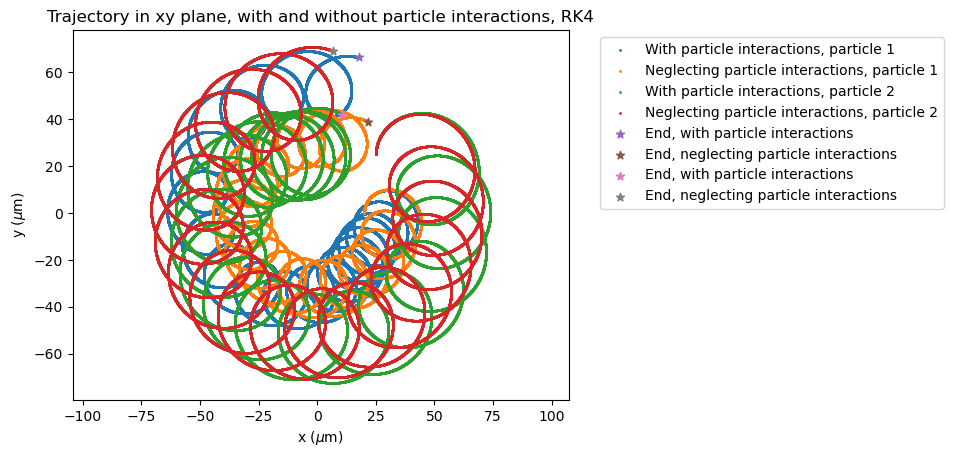

In [13]:
with_data = pd.read_csv("../Project3_Outputs/twoparticles_n32000_RK4_withinteractions.csv")
without_data = pd.read_csv("../Project3_Outputs/twoparticles_n32000_RK4_nointeractions.csv")

with_data_1 = with_data[with_data['particle']==0]
with_data_2 = with_data[with_data['particle']==1]
without_data_1 = without_data[without_data['particle']==0]
without_data_2 = without_data[without_data['particle']==1]

#Plot
plt.scatter(with_data_1['x'], with_data_1['y'], s=1, label='With particle interactions, particle 1')
plt.scatter(without_data_1['x'], without_data_1['y'], s=1, label='Neglecting particle interactions, particle 1')
plt.scatter(with_data_2['x'], with_data_2['y'], s=1, label='With particle interactions, particle 2')
plt.scatter(without_data_2['x'], without_data_2['y'], s=1, label='Neglecting particle interactions, particle 2')
plt.scatter(with_data_1['x'].iloc[-1], with_data_1['y'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_1['x'].iloc[-1], without_data_1['y'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.scatter(with_data_2['x'].iloc[-1], with_data_2['y'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_2['x'].iloc[-1], without_data_2['y'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Trajectory in xy plane, with and without particle interactions, RK4')
plt.xlabel(r'x ($\mu$m)')
plt.ylabel(r'y ($\mu$m)')
plt.savefig('../Figures/xy plane with and without interactions.pdf', bbox_inches='tight')

# Plots 5 and 6

Phase space plots, (x,vx) and (z, vz)

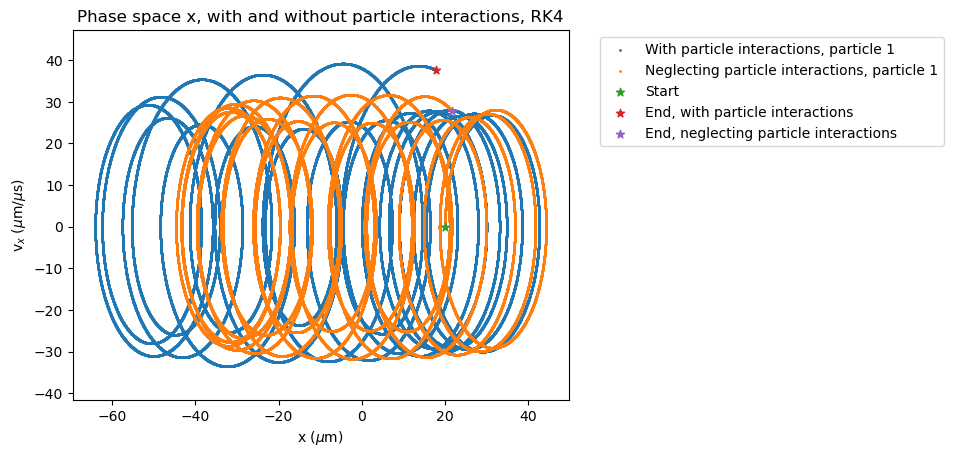

In [17]:
plt.scatter(with_data_1['x'], with_data_1['vx'], s=1, label='With particle interactions, particle 1')
plt.scatter(without_data_1['x'], without_data_1['vx'], s=1, label='Neglecting particle interactions, particle 1')
plt.scatter(with_data['x'][0], with_data['vx'][0], marker='*', label='Start')
plt.scatter(with_data_1['x'].iloc[-1], with_data_1['vx'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_1['x'].iloc[-1], without_data_1['vx'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Phase space x, with and without particle interactions, RK4')
plt.xlabel(r'x ($\mu$m)')
plt.ylabel(r'v$_x$ ($\mu$m/$\mu$s)')
plt.savefig('../Figures/x plhase space with and without interactions, particle 1.pdf', bbox_inches='tight')

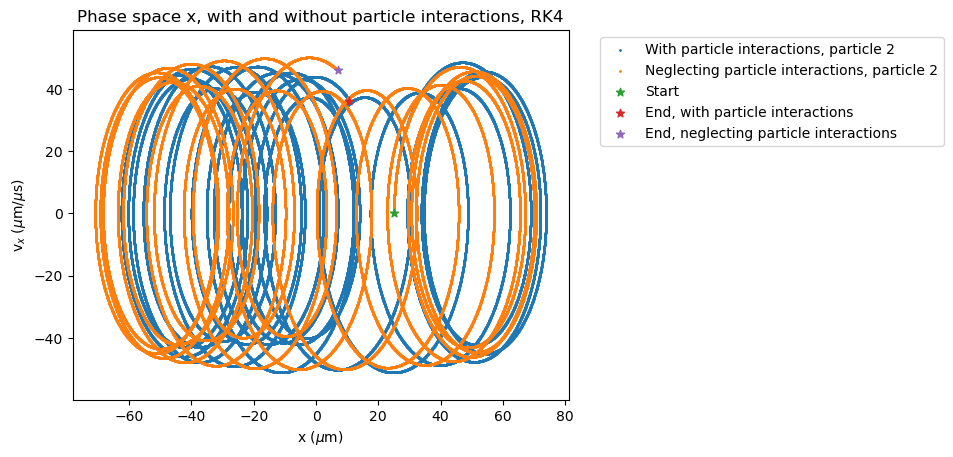

In [16]:
plt.scatter(with_data_2['x'], with_data_2['vx'], s=1, label='With particle interactions, particle 2')
plt.scatter(without_data_2['x'], without_data_2['vx'], s=1, label='Neglecting particle interactions, particle 2')
plt.scatter(with_data_2['x'].iloc[0], with_data_2['vx'].iloc[0], marker='*', label='Start')
plt.scatter(with_data_2['x'].iloc[-1], with_data_2['vx'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_2['x'].iloc[-1], without_data_2['vx'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Phase space x, with and without particle interactions, RK4')
plt.xlabel(r'x ($\mu$m)')
plt.ylabel(r'v$_x$ ($\mu$m/$\mu$s)')
plt.savefig('../Figures/x plhase space with and without interactions, particle 2.pdf', bbox_inches='tight')

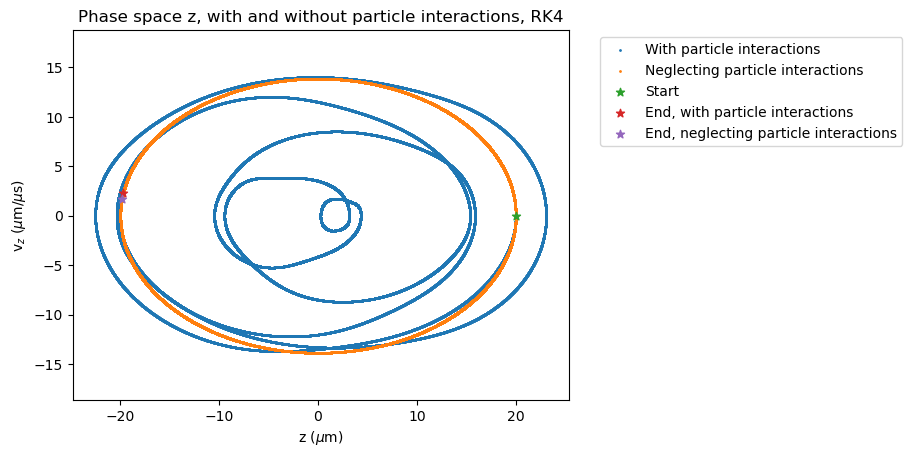

In [10]:
plt.scatter(with_data_1['z'], with_data_1['vz'], s=1, label='With particle interactions')
plt.scatter(without_data_1['z'], without_data_1['vz'], s=1, label='Neglecting particle interactions')
plt.scatter(with_data_1['z'][0], with_data_1['vz'][0], marker='*', label='Start')
plt.scatter(with_data_1['z'].iloc[-1], with_data_1['vz'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_1['z'].iloc[-1], without_data_1['vz'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.axis('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Phase space z, with and without particle interactions, RK4')
plt.xlabel(r'z ($\mu$m)')
plt.ylabel(r'v$_z$ ($\mu$m/$\mu$s)')
plt.savefig('../Figures/z phase space with and without interactions, particle 1.pdf', bbox_inches='tight')

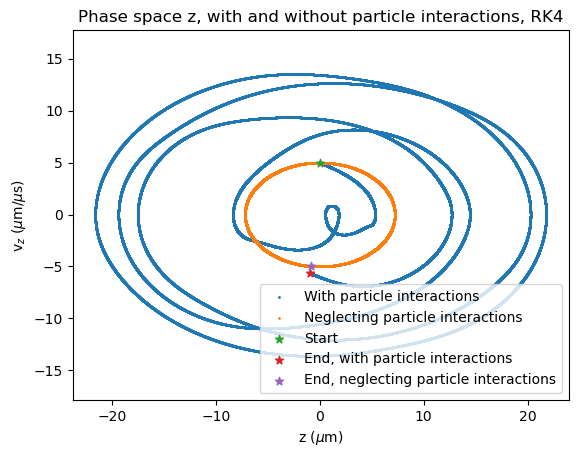

In [13]:
plt.scatter(with_data_2['z'], with_data_2['vz'], s=1, label='With particle interactions')
plt.scatter(without_data_2['z'], without_data_2['vz'], s=1, label='Neglecting particle interactions')
plt.scatter(with_data_2['z'].iloc[0], with_data_2['vz'].iloc[0], marker='*', label='Start')
plt.scatter(with_data_2['z'].iloc[-1], with_data_2['vz'].iloc[-1], marker='*', label='End, with particle interactions')
plt.scatter(without_data_2['z'].iloc[-1], without_data_2['vz'].iloc[-1], marker='*', label='End, neglecting particle interactions')
plt.axis('equal')
plt.legend()
plt.title('Phase space z, with and without particle interactions, RK4')
plt.xlabel(r'z ($\mu$m)')
plt.ylabel(r'v$_z$ ($\mu$m/$\mu$s)')
plt.savefig('../Figures/z phase space with and without interactions, particle 2.pdf', bbox_inches='tight')